In [197]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [198]:
df = pd.read_csv("/content/drive/MyDrive/My Data/train.csv")

In [199]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [200]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [201]:
df.duplicated().sum()

np.int64(0)

<Axes: >

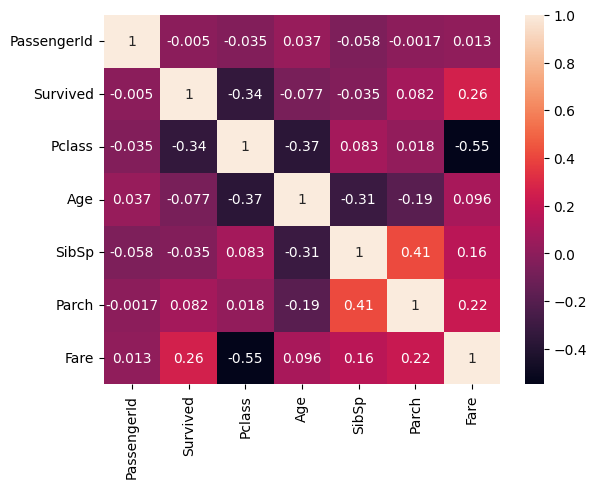

In [202]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

<Axes: xlabel='Survived', ylabel='count'>

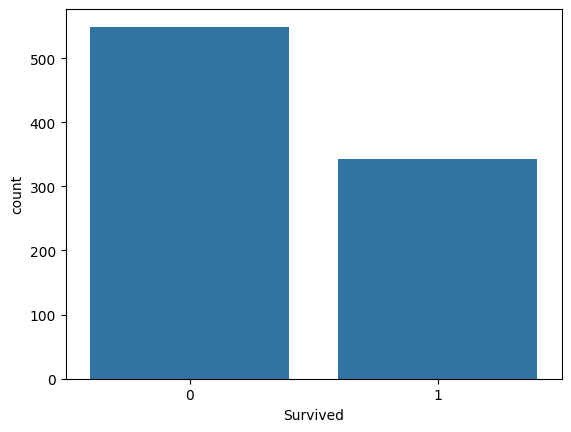

In [203]:
sns.countplot(x=df['Survived'])

<Axes: xlabel='Survived', ylabel='count'>

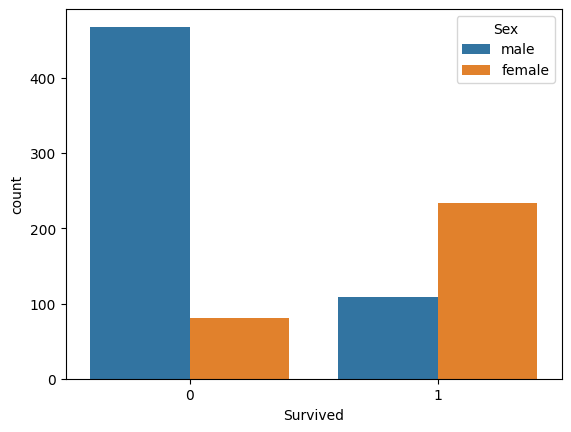

In [204]:
sns.countplot(x='Survived',hue='Sex',data=df)

<Axes: xlabel='Fare', ylabel='Count'>

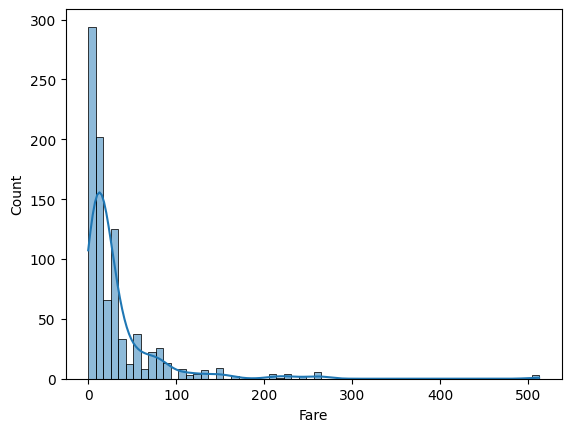

In [205]:
sns.histplot(df['Fare'],kde=True)

<Axes: xlabel='Pclass', ylabel='Survived'>

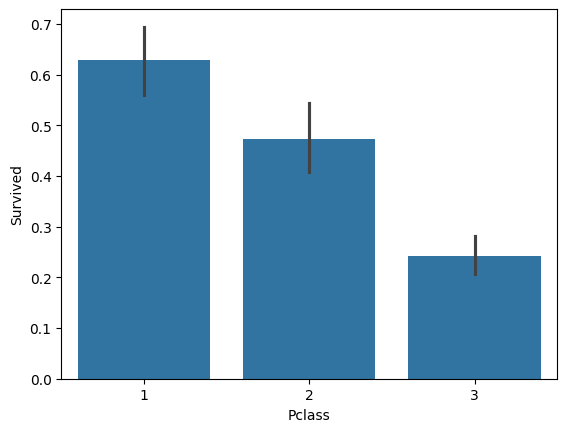

In [206]:
sns.barplot(x='Pclass',y='Survived',data=df)

In [207]:
df_clean = df.drop(['PassengerId','Name','Ticket','Cabin'],axis=1)

In [208]:
df_clean.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [209]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [210]:
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].mean())
df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])

In [211]:

numeric_col = df_clean.select_dtypes(include=np.number)
numeric_col.skew()

,0
Survived,0.478523
Pclass,-0.630548
Age,0.434488
SibSp,3.695352
Parch,2.749117
Fare,4.787317


In [212]:
Q1 = numeric_col.quantile(0.25)
Q3 = numeric_col.quantile(0.75)
IQR = Q3 - Q1

# Create a boolean mask of outliers
outliers_mask = (numeric_col < (Q1 - 1.5 * IQR)) | (numeric_col > (Q3 + 1.5 * IQR))
outliers_mask.sum()

,0
Survived,0
Pclass,0
Age,66
SibSp,46
Parch,213
Fare,116


In [213]:
df_clean.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked'],
      dtype='object')

In [214]:
df_clean['SibSp'].unique()

array([1, 0, 3, 4, 2, 5, 8])

In [215]:
from numpy.random import normal
skew_col = ['Fare']
ordinal_col = ['Embarked']
one_hot_encode = ['Sex']
normal_col = ['Pclass','Age','SibSp','Parch']

X = skew_col + ordinal_col + one_hot_encode + normal_col
y = ['Survived']
#

In [216]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,StandardScaler
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [217]:
skew_pipline = Pipeline(steps=[
    ('log_transform',FunctionTransformer(np.log1p)),
    ('stander_scalar',StandardScaler())
])

ordinal_pipeline = Pipeline(steps=[
    ('ordinal_encoder',OrdinalEncoder())
])

one_hot_pipeline = Pipeline(steps=[
    ('one_hot_encoder',OneHotEncoder(handle_unknown='ignore'))
])

normal_pipeline = Pipeline(steps=[
    ('stander_scalar',StandardScaler())
])

In [218]:
processing_pipeline = ColumnTransformer(transformers=[
    ('skew_pipeline', skew_pipline, skew_col),
    ('ordinal_pipeline', ordinal_pipeline, ordinal_col),
    ('one_hot_pipeline', one_hot_pipeline, one_hot_encode),
    ('normal_col', normal_pipeline, normal_col)
])

In [219]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df_clean[X],df_clean[y],test_size=0.2,random_state=42,stratify=df_clean[y])
#


In [220]:
  from sklearn.linear_model import LogisticRegression
  from sklearn.neighbors import KNeighborsClassifier
  from sklearn.tree import DecisionTreeClassifier
  from sklearn.svm import SVC
  from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [221]:
LR_pipeline = Pipeline(steps=[
    ('processing_pipeline',processing_pipeline),
    ('logistic_regression',LogisticRegression())
])
LR_pipeline.fit(X_train,y_train)
y_pred = LR_pipeline.predict(X_test)
print(accuracy_score(y_test,y_pred))

0.8100558659217877


In [222]:
x_train_p = LR_pipeline.predict(X_train)
print(accuracy_score(y_train,x_train_p))

0.7907303370786517


In [223]:
knn_pipeline = Pipeline(steps=[
    ('processing_pipeline',processing_pipeline),
    ('knn',KNeighborsClassifier(n_neighbors=3))
])
knn_pipeline.fit(X_train,y_train)
k_y_pred = knn_pipeline.predict(X_test)
print(accuracy_score(y_test,k_y_pred))
#

0.7877094972067039


In [224]:
Des_pipeline = Pipeline(steps=[
    ('processing_pipeline',processing_pipeline),
    ('des',DecisionTreeClassifier())
])
Des_pipeline.fit(X_train,y_train)
d_y_pred = Des_pipeline.predict(X_test)
print(accuracy_score(y_test,d_y_pred))
#

0.8100558659217877


In [225]:
from sklearn.model_selection import RandomizedSearchCV

In [226]:
perms = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

In [227]:
best_pipeline = RandomizedSearchCV(
    estimator=Des_pipeline,
    param_distributions=perms,
    cv=5,
    n_iter=10,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

In [228]:
# Update parameter distributions to target the 'des' step inside Des_pipeline
perms_fixed = {
    'des__max_depth': [None, 5, 10, 15],
    'des__min_samples_split': [2, 5, 10],
    'des__min_samples_leaf': [1, 2, 4],
    'des__criterion': ['gini', 'entropy']
}

# Re-initialize RandomizedSearchCV with correct parameter keys
best_pipeline = RandomizedSearchCV(
    estimator=Des_pipeline,
    param_distributions=perms_fixed,
    cv=5,
    n_iter=10,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

# Fit the pipeline on training data

In [232]:
# Fit the search pipeline first to find the best estimator
best_pipeline.fit(X_train, y_train)

# Retrieve and display the best estimator and parameters
best_model = best_pipeline.best_estimator_
print("Best parameters:", best_pipeline.best_params_)


Best parameters: {'des__min_samples_split': 5, 'des__min_samples_leaf': 1, 'des__max_depth': 5, 'des__criterion': 'gini'}


In [233]:
b_y_pred = best_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, b_y_pred))

print(classification_report(y_test, b_y_pred))

Accuracy: 0.7653631284916201
              precision    recall  f1-score   support

           0       0.77      0.88      0.82       110
           1       0.75      0.58      0.66        69

    accuracy                           0.77       179
   macro avg       0.76      0.73      0.74       179
weighted avg       0.76      0.77      0.76       179



In [239]:
Svm_pipeline = Pipeline(steps=[
    ('processing_pipeline',processing_pipeline),
    ('svm',SVC(C=1.0, kernel='rbf', gamma='auto'))
])
Svm_pipeline.fit(X_train,y_train)
s_y_pred = Svm_pipeline.predict(X_test)

In [240]:
print(accuracy_score(y_test,s_y_pred))
#

0.8212290502793296


In [241]:
x_train_s = Svm_pipeline.predict(X_train)
print(accuracy_score(y_train,x_train_s))
#

0.8342696629213483


In [242]:
result  = pd.DataFrame({
    'Model':['Logistic Regression','KNN','Decision Tree','SVM'],
    'Accuracy':[accuracy_score(y_test,y_pred),accuracy_score(y_test,k_y_pred),accuracy_score(y_test,d_y_pred),accuracy_score(y_test,s_y_pred)],
    'confusion_matrix':[confusion_matrix(y_test,y_pred),confusion_matrix(y_test,k_y_pred),confusion_matrix(y_test,d_y_pred),confusion_matrix(y_test,s_y_pred)]
})


In [243]:
result

,Model,Accuracy,confusion_matrix
0,Logistic Regression,0.810056,"[[97, 13], [21, 48]]"
1,KNN,0.787709,"[[92, 18], [20, 49]]"
2,Decision Tree,0.810056,"[[95, 15], [19, 50]]"
3,SVM,0.821229,"[[99, 11], [21, 48]]"


In [244]:
import joblib
model = joblib.dump(Svm_pipeline,'Svm_model.pkl')

In [245]:
df_clean.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked'],
      dtype='object')